# Figure S11

**Tuned conventional image-processing pipelines generalise worse than Mycol**

- **Panels** — **a** parameter-search convergence · **b** true vs predicted count on training and held-out images ·
  **c** MAPE on training and held-out images
- **Needs** — `case_study_1/conventional_baseline_output/` (written by `case_study_1/conventional_baseline.ipynb`):
  the search caches, `train_predictions.csv` and `test_predictions.csv`
- **Writes** — `output/Figure_S11.png` at 300 dpi
- **Kernel** — `mycol_colonies_env`, run from this directory, top to bottom

In [1]:
import io
import json
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont
from plotly.colors import hex_to_rgb
from plotly.subplots import make_subplots

BASELINE = Path("../../../case_study_1/conventional_baseline_output")
OUTPUT = Path("output")
OUTPUT.mkdir(exist_ok=True)

# the layout Figure 2 uses: a 1788 px canvas rasterised at 300 dpi, every label at 19.5 px
FIG_W, MARGIN, ROW_GAP = 1788, 20, 26
LETTER_H, LETTER_SIZE = 36, 30
TEXT_PX = 19.5
CONTENT_W = FIG_W - 2 * MARGIN
SCALE = 300 / 96                                   # canvas px -> 300 dpi raster px (1788 -> 5588)

DATASETS = ["s_aureus", "bright_ecoli", "mcount"]
LABEL = {"s_aureus": "S. aureus", "bright_ecoli": "E. coli", "mcount": "MCount Dataset"}
COMPARED = ["threshold_cc", "adaptive_cc", "threshold_watershed", "log_blob"]
ORDER = COMPARED + ["mycol", "mcount_tool", "nice"]
PUBLISHED = ("mcount_tool", "nice")                # counts from the original MCount paper, not re-run
PUBLISHED_REF = "Chen et al. 2025"
MNAME = {"threshold_cc": "Global threshold", "adaptive_cc": "Local threshold",
         "threshold_watershed": "Threshold + watershed", "log_blob": "LoG + Find Maxima",
         "mycol": "Mycol-trained cyto2",
         "mcount_tool": "MCount", "nice": "NICE"}
COLOR = {"threshold_cc": "#5289C7", "adaptive_cc": "#4EB265", "threshold_watershed": "#882E72",
         "log_blob": "#E8601C"}                    # Tol, as in Figures 3-4
SPLIT_COLOR = {"tune": "#D55E00", "test": "#56B4E9"}
INK, SUB, NEUTRAL = "#0f172a", "#334155", "#94a3b8"
N_STARTUP = 50                                     # random start-up trials of every search

axis_style = dict(showline=True, linecolor=INK, ticks="outside", zeroline=False, showgrid=False,
                  gridcolor="#ededed", title=dict(standoff=8, font=dict(size=TEXT_PX)), tickfont=dict(size=TEXT_PX))
pio.templates["paper"] = go.layout.Template(layout=dict(
    font=dict(family="Helvetica, Arial, sans-serif", size=TEXT_PX, color=INK), paper_bgcolor="white",
    plot_bgcolor="white", xaxis=axis_style, yaxis=axis_style, annotationdefaults=dict(showarrow=False),
    legend=dict(bgcolor="rgba(255,255,255,0)", font=dict(size=TEXT_PX))))
pio.templates.default = "paper"


def tint(color, t):
    """Hex colour mixed with white by t (0 = the colour, 1 = white)."""
    return "rgb({}, {}, {})".format(*(round(v * (1 - t) + 255 * t) for v in hex_to_rgb(color)))


def axis_ids(fig, row, col):
    sp = fig.get_subplot(row, col)
    return sp.xaxis.plotly_name.replace("axis", ""), sp.yaxis.plotly_name.replace("axis", "")


def left_titles(fig):
    """Left-align the subplot titles over their panels, at the figure's one type size."""
    starts = {round(sum(a.domain) / 2, 6): a.domain[0] for a in fig.select_xaxes()}
    for a in fig.layout.annotations:
        if round(a.x, 6) in starts:
            a.update(x=starts[round(a.x, 6)], xanchor="left", align="left", font=dict(size=TEXT_PX))


def mape(true, pred):
    true, pred = np.asarray(true, float), np.asarray(pred, float)
    return float(np.mean(np.abs(pred - true) / true) * 100)


def boot_ci(ape, n=4000, seed=0):
    """95% percentile bootstrap CI of the mean over images - as in conventional_baseline.ipynb."""
    rng = np.random.default_rng(seed)
    ape = np.asarray(ape)
    return np.percentile(ape[rng.integers(0, len(ape), (n, len(ape)))].mean(axis=1), [2.5, 97.5])

In [2]:
PRED = pd.concat([pd.read_csv(BASELINE / "train_predictions.csv").assign(split="tune"),
                  pd.read_csv(BASELINE / "test_predictions.csv").assign(split="test")], ignore_index=True)
PRED = PRED[PRED["method"].isin(ORDER)]
TRACES = {(k, m): [t[0] for t in json.loads((BASELINE / "search" / f"{k}__{m}.json").read_text())["trace"]]
          for k in DATASETS for m in COMPARED}


def counts(key, m, split):
    d = PRED[(PRED["dataset"] == key) & (PRED["method"] == m) & (PRED["split"] == split)]
    return d["true_count"].to_numpy(float), d["pred_count"].to_numpy(float)


N = {(k, s): PRED[(PRED["dataset"] == k) & (PRED["split"] == s)]["image"].nunique() for k in DATASETS
     for s in ("tune", "test")}
for k in DATASETS:
    print(f"{LABEL[k]:10s} {N[k, 'tune']:3d} training / {N[k, 'test']:3d} held-out images, "
          f"{len(TRACES[k, COMPARED[0]])} trials per search")

S. aureus    9 training /  37 held-out images, 400 trials per search
E. coli     13 training /  52 held-out images, 400 trials per search
MCount Dataset  40 training / 494 held-out images, 150 trials per search


In [3]:
# --- panel a: best tuning-set MAPE found so far, per Optuna trial ---
fig_a = make_subplots(1, 3, horizontal_spacing=0.07, subplot_titles=[LABEL[k] for k in DATASETS])
left_titles(fig_a)
for c, key in enumerate(DATASETS, start=1):
    best = {m: np.minimum.accumulate(TRACES[key, m]) for m in COMPARED}
    for m, b in best.items():
        fig_a.add_trace(go.Scatter(x=np.arange(1, len(b) + 1), y=b, mode="lines", name=MNAME[m], showlegend=c == 1,
                                   line=dict(color=COLOR[m], width=2.5)), 1, c)
    fig_a.add_vline(x=N_STARTUP, line=dict(color=NEUTRAL, dash="dot", width=1.5), row=1, col=c)
    lo, hi = min(b[-1] for b in best.values()) * 0.8, max(b[0] for b in best.values()) * 1.25
    fig_a.update_yaxes(type="log", range=np.log10([lo, hi]), showgrid=True,
                       tickvals=[v for v in (2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000) if lo <= v <= hi],
                       row=1, col=c)
    fig_a.update_xaxes(title_text="Optuna Trial", showgrid=True, row=1, col=c)
fig_a.update_yaxes(title_text="Best Tuning MAPE (%)", row=1, col=1)
fig_a.update_layout(width=CONTENT_W, height=470, margin=dict(l=95, r=10, t=95, b=75),
                    legend=dict(orientation="h", x=0, y=1, yref="container", yanchor="top"))

In [4]:
# --- panel b: true vs predicted count, training (red) over held-out (blue) images ---
cols = COMPARED + ["mycol"]
hgap, vgap, margin_b = 45, 62, dict(l=110, r=10, t=95, b=75)
cell = (CONTENT_W - margin_b["l"] - margin_b["r"] - (len(cols) - 1) * hgap) / len(cols)
pw, ph = len(cols) * cell + (len(cols) - 1) * hgap, 3 * cell + 2 * vgap
fig_b = make_subplots(3, len(cols), horizontal_spacing=hgap / pw, vertical_spacing=vgap / ph,
                      subplot_titles=[MNAME[m] for m in cols] + [""] * (2 * len(cols)))
left_titles(fig_b)


def row_limit(key):
    """One scale per row: the largest count in the row, capped at 1.5x the largest true count."""
    true_max = max(counts(key, m, s)[0].max() for m in cols for s in ("tune", "test"))
    pred_max = max(counts(key, m, s)[1].max() for m in cols for s in ("tune", "test"))
    return min(max(true_max, pred_max), 1.5 * true_max) * 1.08


def tick_step(lim):
    """Largest 1/2/5 x 10^n step that still puts at least 3 ticks (0, step, 2 step) on a 0-lim axis."""
    return max(f * 10 ** e for e in range(-1, 6) for f in (1, 2, 5) if 2 * f * 10 ** e <= lim)


for r, key in enumerate(DATASETS, start=1):
    lim = row_limit(key)
    for c, m in enumerate(cols, start=1):
        fig_b.add_trace(go.Scatter(x=[0, lim], y=[0, lim], mode="lines", showlegend=False,
                                   line=dict(color="#8a8a8a", width=1.2, dash="dash")), r, c)
        n_off = 0
        for split in ("test", "tune"):             # held-out underneath (many), training on top (few)
            t, p = counts(key, m, split)
            on, many = p <= lim, len(t) > 100
            marker = (dict(size=5 if many else 7, opacity=0.5 if many else 0.7, color=SPLIT_COLOR[split])
                      if split == "test" else dict(size=9, color=SPLIT_COLOR[split], line=dict(color="white", width=1)))
            fig_b.add_trace(go.Scatter(x=t[on], y=p[on], mode="markers", marker=marker,
                                       name="held-out test images" if split == "test" else "training images",
                                       legendrank=2 if split == "test" else 1, showlegend=(r, c) == (1, 1)), r, c)
            if (~on).any():                        # off-scale predictions: open circles on the top edge
                fig_b.add_trace(go.Scatter(x=t[~on], y=np.full((~on).sum(), lim * 0.985), mode="markers",
                                           cliponaxis=False, showlegend=False,
                                           marker=dict(symbol="circle-open", size=7, color=SPLIT_COLOR[split],
                                                       line_width=1.2)), r, c)
                n_off += int((~on).sum())
        xa, ya = axis_ids(fig_b, r, c)
        dom = dict(xref=f"{xa} domain", yref=f"{ya} domain")
        if n_off:
            fig_b.add_annotation(**dom, x=0.97, y=0.03, xanchor="right", yanchor="bottom",
                                 text=f"{n_off} off-scale", font=dict(color=SUB))
        fig_b.add_annotation(**dom, x=0.03, y=0.97, xanchor="left", yanchor="top", align="left",
                             text=f"train {mape(*counts(key, m, 'tune')):.2f}%<br>"
                                  f"test {mape(*counts(key, m, 'test')):,.2f}%",
                             bgcolor="white", bordercolor="#dddddd", borderpad=3)
        ticks = dict(range=[-lim * 0.02, lim], showgrid=True, tick0=0, dtick=tick_step(lim))
        fig_b.update_xaxes(**ticks, row=r, col=c)
        fig_b.update_yaxes(**ticks, row=r, col=c)
    fig_b.update_yaxes(title_text=f"{LABEL[key]}<br>Predicted Count", row=r, col=1)
fig_b.update_xaxes(title_text="True Count", row=3)
fig_b.update_layout(width=CONTENT_W, height=margin_b["t"] + ph + margin_b["b"], margin=margin_b,
                    legend=dict(orientation="h", x=0, y=1, yref="container", yanchor="top"))

In [5]:
# --- panel c: MAPE with 95% bootstrap CI, training (light) and held-out (solid) images ---
CAP, WIDTH = 100, 0.4                              # y axis stops at 100 % MAPE; taller bars are cut
SPLIT_BAR = {"tune": dict(name="training images", tint=0.6), "test": dict(name="held-out test images", tint=0.0)}
fig_c = make_subplots(1, 3, column_widths=[6, 6, 8], horizontal_spacing=0.06,
                      subplot_titles=[LABEL[k] for k in DATASETS])
left_titles(fig_c)
for col, key in enumerate(DATASETS, start=1):
    ms = [m for m in ORDER if len(counts(key, m, "test")[0])]
    bars = []                                      # (x, method, split, MAPE, CI low, CI high)
    for i, m in enumerate(ms):
        splits = [s for s in ("tune", "test") if len(counts(key, m, s)[0])]
        for j, s in enumerate(splits):
            t, p = counts(key, m, s)
            ape = np.abs(p - t) / t * 100
            bars.append((i + (j - (len(splits) - 1) / 2) * WIDTH, m, s, ape.mean(), *boot_ci(ape)))
    top = min(CAP, max(b[5] for b in bars)) * 1.15
    for s, style in SPLIT_BAR.items():
        b = [bar for bar in bars if bar[2] == s]
        fig_c.add_trace(go.Bar(x=[x for x, *_ in b], y=[min(v, top) for *_, v, _, _ in b], width=WIDTH,
                               showlegend=col == 1, name=style["name"],
                               marker=dict(color=tint(NEUTRAL, style["tint"]), opacity=0.85,
                                           line=dict(color=INK, width=1.2))), 1, col)
    ci = [bar for bar in bars if bar[5] <= top]
    fig_c.add_trace(go.Scatter(x=[b[0] for b in ci], y=[b[3] for b in ci], mode="markers", marker_opacity=0,
                               showlegend=False,
                               error_y=dict(type="data", symmetric=False, color=INK, thickness=1.2, width=4,
                                            array=[b[5] - b[3] for b in ci], arrayminus=[b[3] - b[4] for b in ci])),
                    1, col)
    for x, m, s, v, lo, hi in bars:
        cut = v > top
        fig_c.add_annotation(x=x, y=top * 0.975 if cut else (hi if hi <= top else v) + top * 0.012,
                             text=f"<b>{v:,.2f}</b>" if cut else f"{v:.2f}",
                             textangle=-90 if cut else 0, yanchor="top" if cut else "bottom",
                             font=dict(size=14), row=1, col=col)
    fig_c.update_yaxes(range=[0, top], showgrid=True, row=1, col=col)
    fig_c.update_xaxes(tickvals=list(range(len(ms))), ticks="", tickangle=-40,
                       ticktext=[MNAME[m] for m in ms], row=1, col=col)
    pub = [b for b in bars if b[1] in PUBLISHED]
    if pub:                                            # bracket over the published tools' bars, with their source
        x0, x1 = min(b[0] for b in pub) - WIDTH / 2, max(b[0] for b in pub) + WIDTH / 2
        yb = max(min(b[5], top) for b in pub) + top * 0.14
        fig_c.add_shape(type="path", path=f"M{x0},{yb - top * 0.05} V{yb} H{x1} V{yb - top * 0.05}",
                      line=dict(color=SUB, width=1.5), row=1, col=col)
        fig_c.add_annotation(x=(x0 + x1) / 2, y=yb + top * 0.01, text=PUBLISHED_REF, yanchor="bottom",
                           font=dict(size=16, color=SUB), row=1, col=col)
fig_c.update_yaxes(title_text="MAPE (%)", row=1, col=1)
fig_c.update_layout(width=CONTENT_W, height=660, margin=dict(l=85, r=10, t=95, b=200), barmode="overlay",
                    legend=dict(orientation="h", x=0, y=1, yref="container", yanchor="top"))

letter font ('Helvetica', 'Bold'); wrote output/Figure_S11.png  5588 x 7790 px (18.6 x 26.0 in at 300 dpi)


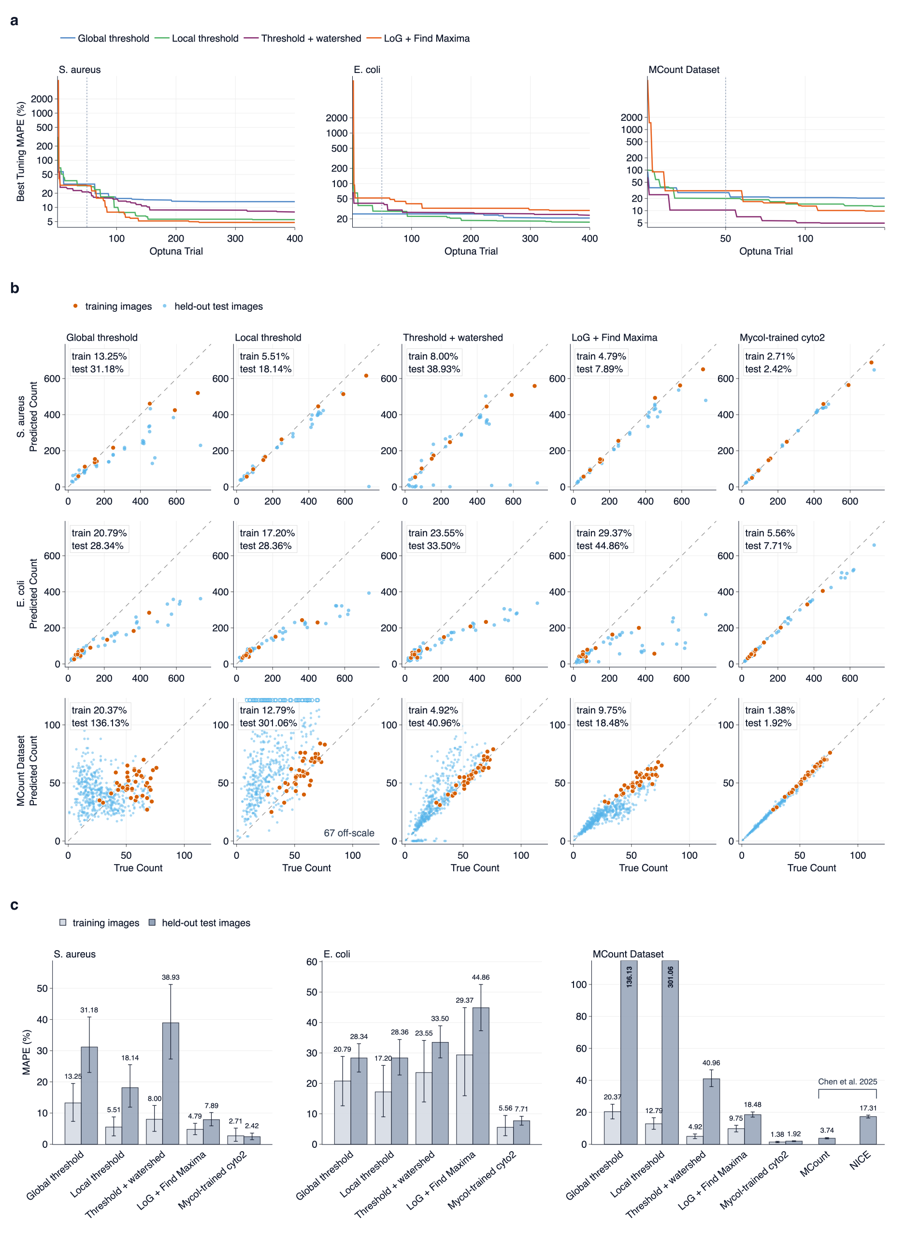

In [6]:
# --- assembly: panels stacked on the 1788 px canvas, lettered as in Figure 2, rasterised at 300 dpi ---
panels = [("a", fig_a), ("b", fig_b), ("c", fig_c)]
rasters = [Image.open(io.BytesIO(f.to_image(format="png", scale=SCALE))).convert("RGB") for _, f in panels]
heights = [f.layout.height for _, f in panels]
fig_h = MARGIN + sum(LETTER_H + h for h in heights) + ROW_GAP * (len(panels) - 1) + MARGIN

canvas = Image.new("RGB", (round(FIG_W * SCALE), round(fig_h * SCALE)), "white")
draw = ImageDraw.Draw(canvas)
letter_font = ImageFont.truetype("/System/Library/Fonts/Helvetica.ttc", round(LETTER_SIZE * SCALE), index=1)
y = MARGIN
for (letter, _), im, h in zip(panels, rasters, heights):
    draw.text((MARGIN * SCALE, (y + LETTER_SIZE) * SCALE), letter, font=letter_font, fill=INK, anchor="ls")
    canvas.paste(im, (round(MARGIN * SCALE), round((y + LETTER_H) * SCALE)))
    y += LETTER_H + h + ROW_GAP

out = OUTPUT / "Figure_S11.png"
canvas.save(out, dpi=(300, 300))
print(f"letter font {letter_font.getname()}; wrote {out}  {canvas.width} x {canvas.height} px "
      f"({canvas.width / 300:.1f} x {canvas.height / 300:.1f} in at 300 dpi)")
preview = canvas.copy()
preview.thumbnail((900, 1400))
display(preview)